### Lagrangian initial conditions

In [40]:
import sys; sys.path.insert(0, '..')
import numpy as np, matplotlib.pyplot as plt
from scripts.exercise_1 import Cosmology
from scripts.exercise_3 import *

#### Gaussian field
$\delta(x)=\frac1V\sum_k\delta_k e^{ik\cdot x}$, $\langle|\delta_k|^2\rangle=VP_L(k)$.

In [41]:
N, L = 128, 1000.0 # number of grid cells per side and box size [Mpc/h]
a_ref = 1.0       # a_ref at which P_L(k) is computed (z = 0), with D1(a_ref) = 1.0
a_i = 0.01
ns = 0.965
V = L**3
cosmo = Cosmology(Omega_m0=0.3135, Omega_lambda0=0.6865)
D, f = cosmo.growing_mode(np.array([a_i, a_ref]), a_i=min(1e-3, a_i, a_ref))  # D, f at a_i and at a_ref
D1_i, f1_i = D[0] / D[1], f[0]   # D1(a_i)/D1(a_ref) and dlnD1/dlna at a_i, as scalars

*_, k_mag = kgrid(N, L) # Fourier space grid in h/Mpc
mask = k_mag > 0        # mask for zero mode

Pk_camb = Pk_CAMB(a_ref, kmax=10.0)

sigma2_camb = Pk_camb(k_mag[mask]).sum() / V # variance of CAMB spectrum on the grid
A = sigma2_camb * V/(k_mag[mask]**(ns-3)).sum() # amplitude of the power-law spectrum in order to have same variance as CAMB
Pk_pl = Pk_powerlaw(A, ns)
print(f"A = {A:.3e} (Mpc/h)^(3+ns);  sigma_delta_ref (CAMB, a_ref) = {np.sqrt(sigma2_camb):.2f}")
print(f"a_ref = {a_ref}, a_i = {a_i} (z = {1/a_i - 1:.0f}): D1(a_i) = {D1_i:.4f}, f1(a_i) = {f1_i:.4f}")

rng = np.random.default_rng(42)

A = 6.369e+01 (Mpc/h)^(3+ns);  sigma_delta_ref (CAMB, a_ref) = 1.29
a_ref = 1.0, a_i = 0.01 (z = 99): D1(a_i) = 0.0127, f1(a_i) = 1.0000


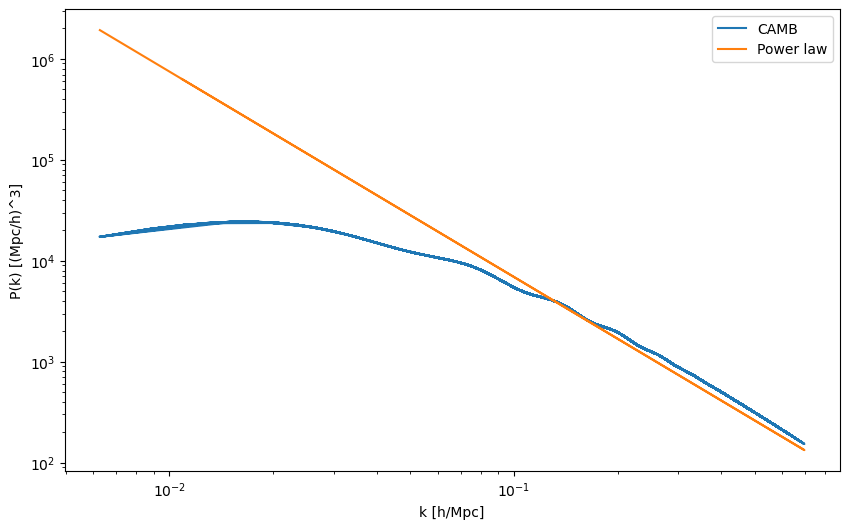

In [42]:
#plot p(k) from camb and power law
plt.figure(figsize=(10, 6))
plt.loglog(k_mag[mask], Pk_camb(k_mag[mask]), label='CAMB')
plt.loglog(k_mag[mask], Pk_pl(k_mag[mask]), label='Power law')
plt.xlabel('k [h/Mpc]')
plt.ylabel('P(k) [(Mpc/h)^3]')
plt.legend()
plt.show()

In [43]:
delta_ref_k_camb = gaussian_field(Pk_camb, N, L, rng)
delta_ref_k_pl = gaussian_field(Pk_pl, N, L, rng)
delta_ref_x_camb = real_space_field(delta_ref_k_camb, N, L)
delta_ref_x_pl = real_space_field(delta_ref_k_pl, N, L)

In [44]:
# Gaussian field checks
for name, dk, Pk in (('CAMB', delta_ref_k_camb, Pk_camb), ('power law', delta_ref_k_pl, Pk_pl)):
    c = check_gaussian_field(dk, N, L, Pk, rng)
    print(f"[{name}] zero mode = {c['zero_mode']:.1e} | mean delta = {c['mean_delta']:.1e}")
    print(f"[{name}] Hermitian relative error = {c['hermitian_rel_err']:.1e} | max|Im delta(x)| / max|delta(x)| = {c['imag_rel_ifft']:.1e}")
    print(f"[{name}] self-conjugate cells: max|Im| = {c['imag_selfconj']:.1e} | <|delta_k|^2/(V P)> = {c['selfconj_mean']:.3f} | z = {c['selfconj_z']:.2f} (|z| < 4)")


[CAMB] zero mode = 0.0e+00 | mean delta = 8.7e-19
[CAMB] Hermitian relative error = 0.0e+00 | max|Im delta(x)| / max|delta(x)| = 2.4e-16
[CAMB] self-conjugate cells: max|Im| = 0.0e+00 | <|delta_k|^2/(V P)> = 0.984 | z = -0.65 (|z| < 4)
[power law] zero mode = 0.0e+00 | mean delta = 0.0e+00
[power law] Hermitian relative error = 0.0e+00 | max|Im delta(x)| / max|delta(x)| = 2.5e-16
[power law] self-conjugate cells: max|Im| = 0.0e+00 | <|delta_k|^2/(V P)> = 0.984 | z = -0.66 (|z| < 4)


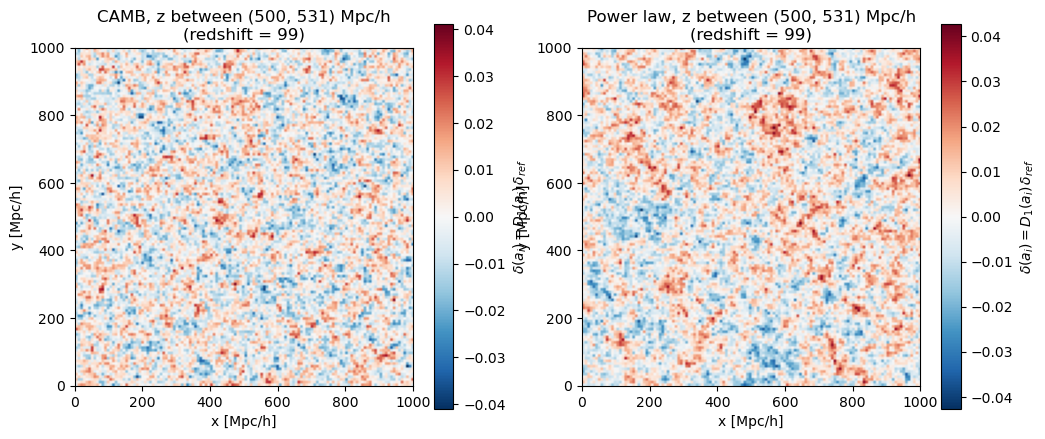

In [45]:
# projection of delta(x, a_i) = D1(a_i) delta_ref(x) on a z axis slice: 
# average over 4 consecutive z-planes
iz, thickness = N//2, 4
planes = (iz + np.arange(thickness))
fig, axs = plt.subplots(1, 2, figsize=(12, 5))
for ax, f, t in zip(axs, (delta_ref_x_camb, delta_ref_x_pl), ('CAMB', 'Power law')):
    f = f[0]
    img = D1_i * f[:, :, planes].mean(axis=2)   
    #img = f[:, :, planes].mean(axis=2)
    vmax = np.abs(img).max()                       
    im = ax.imshow(img.T, origin='lower', extent=[0, L, 0, L], cmap='RdBu_r', vmin=-vmax, vmax=vmax)  # .T: imshow puts axis 0 vertical
    plt.colorbar(im, ax=ax, label=r'$\delta(a_i)=D_1(a_i)\,\delta_{ref}$')
    ax.set_title(f'{t}, z between ({planes[0]*L/N:.0f}, {(planes[-1]+1)*L/N:.0f}) Mpc/h\n(redshift = {1/a_i - 1:.0f})')
    ax.set_xlabel('x [Mpc/h]'); ax.set_ylabel('y [Mpc/h]')
plt.show()

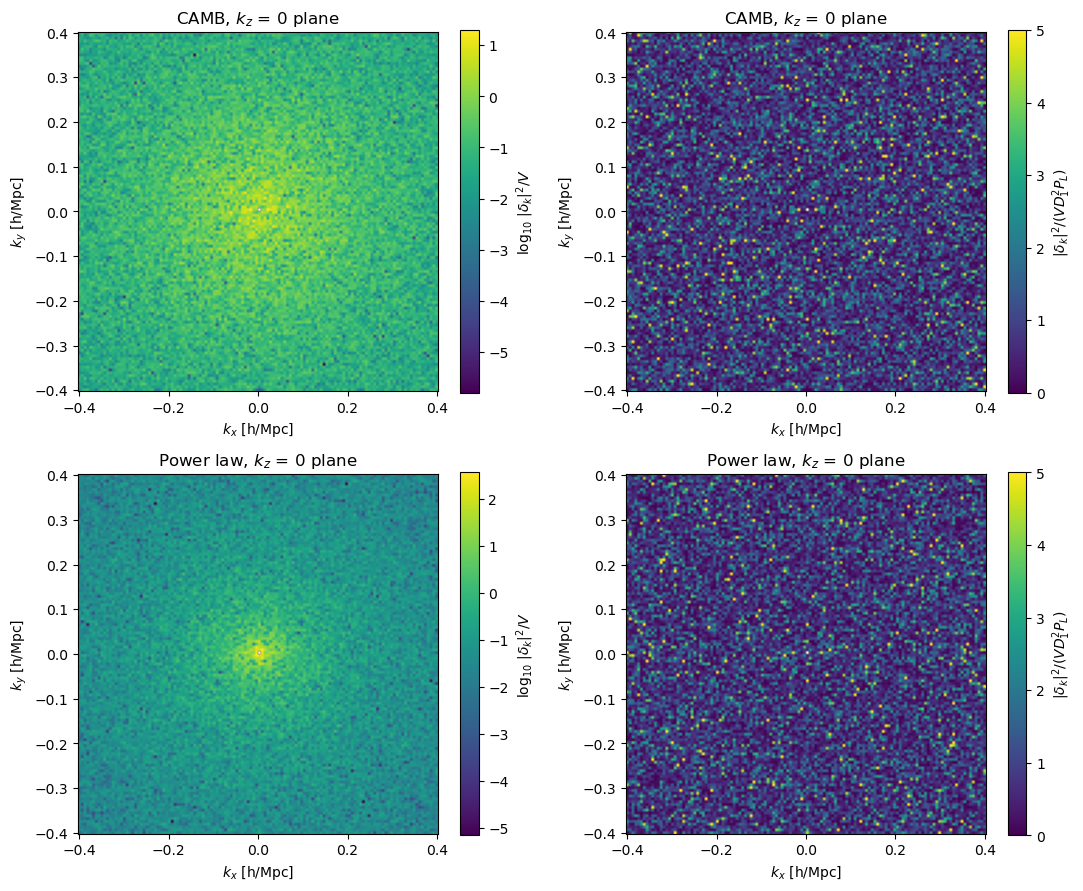

In [46]:
# Fourier-space view of delta(k, a_i) = D1(a_i) delta_ref,k on the plane k_z = 0 (index ikz in FFT ordering)
# left: |delta_k|^2 / V in log scale (the shape of P(k)); right: |delta_k|^2 / (V P(k)) (should look like unit-mean speckle)
ikz = 0                                                   # FFT index of k_z = 0 (indices 1..N/2-1 are k_z > 0)
kN = np.pi * N / L                                        # Nyquist wavenumber
fig, axs = plt.subplots(2, 2, figsize=(11, 9))
for row, (dk, Pk, t) in zip(axs, ((delta_ref_k_camb, Pk_camb, 'CAMB'), (delta_ref_k_pl, Pk_pl, 'Power law'))):
    dk_i = D1_i * dk[:, :, ikz]                           # (N, N): index 0 = kx, index 1 = ky
    p = np.abs(dk_i)**2 / V                               # |delta_k|^2 / V, to be compared with D1^2 P_L(k)
    with np.errstate(invalid='ignore', divide='ignore'):  # the zero mode gives 0/0 (set to nan just below)
        ratio = p / (D1_i**2 * Pk(k_mag[:, :, ikz]))      # <ratio> = 1 for every k if the amplitudes are right
    p[0, 0] = ratio[0, 0] = np.nan                        # zero mode is exactly 0 (no log, no P(0))
    for ax, img, lab, kw in ((row[0], np.log10(p), r'$\log_{10}\,|\delta_k|^2/V$', {}),
                             (row[1], ratio, r'$|\delta_k|^2/(V D_1^2 P_L)$', dict(vmin=0, vmax=5))):
        im = ax.imshow(np.fft.fftshift(img).T, origin='lower', extent=[-kN, kN, -kN, kN], cmap='viridis', **kw)  # fftshift puts k = 0 in the centre
        plt.colorbar(im, ax=ax, label=lab)
        ax.set_title(f'{t}, $k_z$ = 0 plane'); ax.set_xlabel('$k_x$ [h/Mpc]'); ax.set_ylabel('$k_y$ [h/Mpc]')
plt.tight_layout(); plt.show()

#### ZA positions and velocities
$\Psi_k = i D_1(a_i)\,\mathbf{k}\,\delta_{ref,k}/k^2$, $x_p = q_p + \Psi_p$ (wrapped), $v_p = \mathcal{H}_i f_{1,i}\Psi_p$

In [47]:
H0 = 100.0   # km/s per (Mpc/h): lengths are in Mpc/h, so h is absorbed in the unit
za_camb = Zeldovich(delta_ref_k_camb, N, L, cosmo, a_i, a_ref, H0=H0)
za_pl = Zeldovich(delta_ref_k_pl, N, L, cosmo, a_i, a_ref, H0=H0)

displacement_camb = za_camb.displacement()
displacement_pl = za_pl.displacement()

print(f"D1(a_i) = {za_camb.D1_i:.4f} | f1(a_i) = {za_camb.f1_i:.4f} | H_conf(a_i) = {za_camb.H_a_i:.1f} km/s per Mpc/h")
print(f"cell size = {L/N:.2f} Mpc/h | Np = {len(displacement_camb[2])} = N^3 = {N**3}")

for name, z in (('CAMB', displacement_camb), ('power law', displacement_pl)):
    print(f"[{name}] max |Psi| = {np.abs(z[0]).max():.3f} Mpc/h "
          f"({np.abs(z[0]).max() / (L/N):.2f} cells)")


D1(a_i) = 0.0127 | f1(a_i) = 1.0000 | H_conf(a_i) = 559.9 km/s per Mpc/h
cell size = 7.81 Mpc/h | Np = 2097152 = N^3 = 2097152
[CAMB] max |Psi| = 0.360 Mpc/h (0.05 cells)
[power law] max |Psi| = 0.860 Mpc/h (0.11 cells)


In [48]:
for name, z, d in (('CAMB', za_camb, displacement_camb), ('power law', za_pl, displacement_pl)):
    c = z.check()
    # displacement checks
    print(f"Displacement checks [{name}]:")
    print(f"mean Psi per axis = {c['mean_psi']}")
    print(f"positions in [0, L): {d[2].min() >= 0 and d[2].max() < L}")
    print(f"div Psi = D1 delta_ref: max rel err = {c['div_rel_err']:.1e}")
    print(f"max |curl Psi| / max |D1 delta_ref| = {c['curl_rel']:.1e}")
    print(f"v / (H f Psi) = {c['v_norm']:.6f} \n")

    # particle checks
    print(f"Particle checks [{name}]:")
    print(f"coordinates that crossed box edge = {c['n_wrapped']}")
    print(f"positions in [0, L): {c['in_box']}")
    print(f"particle number unchanged: {c['Np_unchanged']}")
    print(f"center-of-mass shift / std(Psi) = {c['com_shift']:.3e}\n")

Displacement checks [CAMB]:
mean Psi per axis = [-4.33680869e-19 -1.52465931e-20  1.16112997e-19]
positions in [0, L): True
div Psi = D1 delta_ref: max rel err = 4.1e-16
max |curl Psi| / max |D1 delta_ref| = 3.6e-17
v / (H f Psi) = 1.000000 

Particle checks [CAMB]:
coordinates that crossed box edge = 23852
positions in [0, L): True
particle number unchanged: True
center-of-mass shift / std(Psi) = 1.445e-15

Displacement checks [power law]:
mean Psi per axis = [-5.20417043e-18  6.77626358e-20 -1.96994717e-19]
positions in [0, L): True
div Psi = D1 delta_ref: max rel err = 4.4e-16
max |curl Psi| / max |D1 delta_ref| = 3.8e-17
v / (H f Psi) = 1.000000 

Particle checks [power law]:
coordinates that crossed box edge = 38872
positions in [0, L): True
particle number unchanged: True
center-of-mass shift / std(Psi) = 5.725e-17



In [49]:
#checks in finer mesh, different seeds and start epochs
for seed, a_i_ in itertools.product((0, 1), (0.01, 0.05)):
    dk = gaussian_field(Pk_camb, 256, L, np.random.default_rng(seed))
    za = Zeldovich(dk, 256, L, cosmo, a_i_, a_ref)
    c = za.check()
    print("N = ", 256, "seed ", seed, "a_i = ", a_i_)
    print(c)


N =  256 seed  0 a_i =  0.01
{'mean_psi': array([-2.16840434e-19,  1.33407689e-20, -2.32713824e-20]), 'div_rel_err': np.float64(4.1556182276936026e-16), 'curl_rel': np.float64(3.431261786162471e-17), 'mean_psi_rel': np.float64(3.028347914468028e-18), 'v_norm': np.float64(0.9999999999999998), 'n_wrapped': 97873, 'in_box': True, 'Np_unchanged': True, 'com_shift': np.float64(3.2256637082700854e-15)}
N =  256 seed  0 a_i =  0.05
{'mean_psi': array([ 1.30104261e-18,  5.67512075e-20, -2.38409996e-20]), 'div_rel_err': np.float64(4.156069269716905e-16), 'curl_rel': np.float64(3.4212723113082366e-17), 'mean_psi_rel': np.float64(3.6344119259435956e-18), 'v_norm': np.float64(1.0000000000000007), 'n_wrapped': 97873, 'in_box': True, 'Np_unchanged': True, 'com_shift': np.float64(1.416284897391145e-16)}
N =  256 seed  1 a_i =  0.01
{'mean_psi': array([ 0.00000000e+00, -1.10537800e-19, -2.63086862e-20]), 'div_rel_err': np.float64(4.245987072106759e-16), 'curl_rel': np.float64(3.450783842566065e-17), '

#### Recovered power spectrum

$\hat{P}(k) = \frac{1}{(N_k V)} \sum |\delta_k|^2$ for ZA particle and gaussian fields at same epoch $a_i$

Particles are assigned with CIC (window $W=\prod_i\mathrm{sinc}^2(\pi n_i/N_m)$ and deconvolved as $|\delta_k|^2/W^2$)

In [50]:
nbins, kmax_frac = 20, 0.5 # linear shells up to kmax_frac * k_Nyq 
pm_camb = Pk_measurement(delta_ref_k_camb, za_camb, N, L, nbins)
pm_pl = Pk_measurement(delta_ref_k_pl, za_pl, N, L, nbins)
kNyq = np.pi*N / L

print(f"Np = {pm_camb.Np} = N^3 equal-mass particles on a lattice, n_bar = {pm_camb.Np/V:.3e} (h/Mpc)^3")
print(f"Window deconvolved on k <= {kmax_frac} k_Nyq = {kmax_frac*kNyq:.3f} h/Mpc (k_Nyq = {kNyq:.3f} h/Mpc)")
print(f"Estimator: P_hat = 1/(N_k V) sum |delta_k|^2 in {nbins} linear shells\n")
for name, pm in (('CAMB', pm_camb), ('power law', pm_pl)):
    print(f"[{name}] mass on mesh / Np - 1 = {pm.counts.sum()/pm.Np - 1:.1e} | mean particle delta = {pm.delta_part.mean():.1e}")

Np = 2097152 = N^3 equal-mass particles on a lattice, n_bar = 2.097e-03 (h/Mpc)^3
Window deconvolved on k <= 0.5 k_Nyq = 0.201 h/Mpc (k_Nyq = 0.402 h/Mpc)
Estimator: P_hat = 1/(N_k V) sum |delta_k|^2 in 20 linear shells

[CAMB] mass on mesh / Np - 1 = 0.0e+00 | mean particle delta = -3.4e-21
[power law] mass on mesh / Np - 1 = 0.0e+00 | mean particle delta = -1.1e-19


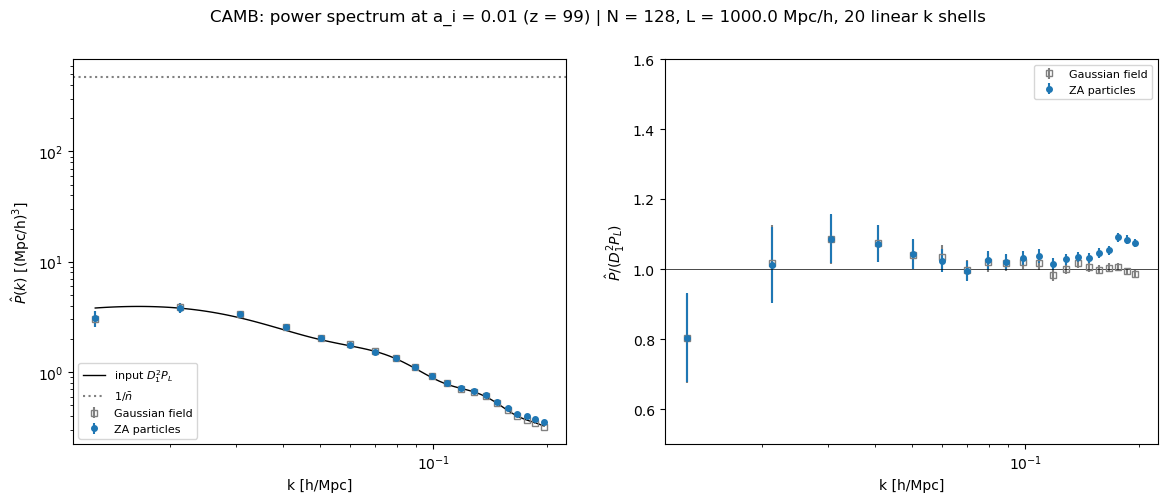

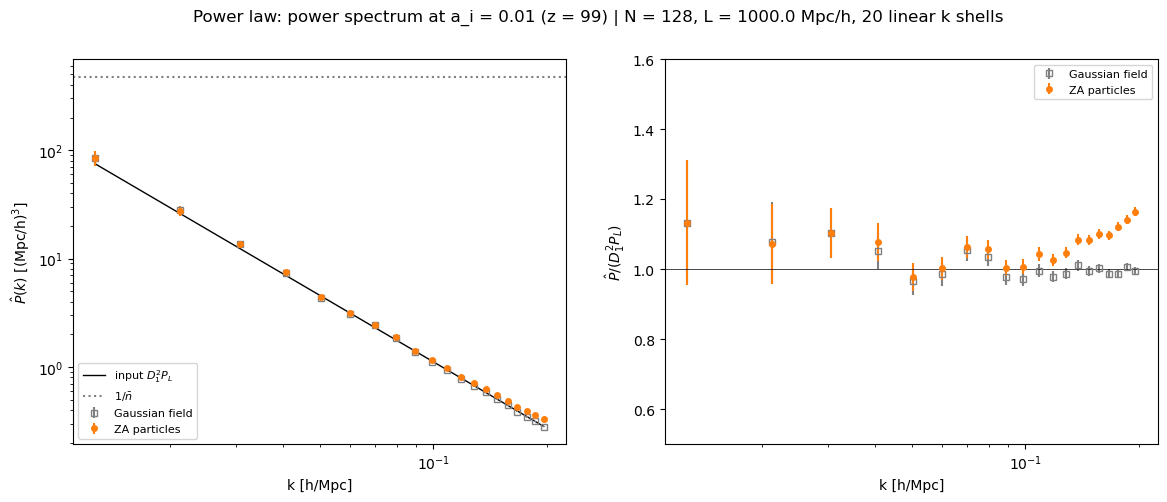

In [51]:
Pk_target = lambda Pk, k: D1_i**2 * Pk(k) # expected P at a_i for the spectrum supplied at a_ref
for name, pm, Pk_in, c in (('CAMB', pm_camb, Pk_camb, 'C0'), ('Power law', pm_pl, Pk_pl, 'C1')):
    kg, Pg, nkg = pm.Pk_measured(nbins, 'gauss', kmax_frac) # P(k) of gaussian field at a_i
    kp, Pp, nkp = pm.Pk_measured(nbins, 'particles', kmax_frac) # P(k) of displaced particles
    egp, epp = np.sqrt(2 / nkg), np.sqrt(2 / nkp) # cosmic-variance error sqrt(2/N_k)
    tg, tp = Pk_target(Pk_in, kg), Pk_target(Pk_in, kp) # expected P at the mean k of each shell
    kk = np.logspace(np.log10(kg[0]), np.log10(kg[-1]), 100)

    fig, axs = plt.subplots(1, 2, figsize=(14, 5))
    axs[0].loglog(kk, Pk_target(Pk_in, kk), 'k-', lw=1, label=r'input $D_1^2P_L$')
    axs[0].errorbar(kg, Pg, Pg*egp, fmt='s', c='gray', ms=4, mfc='none', label='Gaussian field')
    axs[0].errorbar(kp, Pp, Pp*epp, fmt='o', c=c, ms=4, label='ZA particles')
    axs[0].axhline(V/pm.Np, c='gray', ls=':', label=r'$1/\bar n$')
    axs[0].set_xlabel('k [h/Mpc]'); axs[0].set_ylabel(r'$\hat P(k)$ [(Mpc/h)$^3$]'); axs[0].legend(fontsize=8)

    axs[1].errorbar(kg, Pg/tg, Pg/tg*egp, fmt='s', c='gray', ms=4, mfc='none', label='Gaussian field')
    axs[1].errorbar(kp, Pp/tp, Pp/tp*epp, fmt='o', c=c, ms=4, label='ZA particles')
    axs[1].axhline(1, c='k', lw=.5); axs[1].set_xscale('log'); axs[1].set_ylim(0.5, 1.6)
    axs[1].set_xlabel('k [h/Mpc]'); axs[1].set_ylabel(r'$\hat P / (D_1^2 P_L)$'); axs[1].legend(fontsize=8)
    fig.suptitle(f"{name}: power spectrum at a_i = {a_i} (z = {1/a_i - 1:.0f}) | N = {N}, L = {L} Mpc/h, {nbins} linear k shells", fontsize=12)
    plt.show()


[CAMB] N =  32: ZA within 5% of the Gaussian field up to k = 0.048 h/Mpc = 0.48 k_Nyq
[CAMB] N =  64: ZA within 5% of the Gaussian field up to k = 0.097 h/Mpc = 0.48 k_Nyq
[CAMB] N = 128: ZA within 5% of the Gaussian field up to k = 0.145 h/Mpc = 0.36 k_Nyq


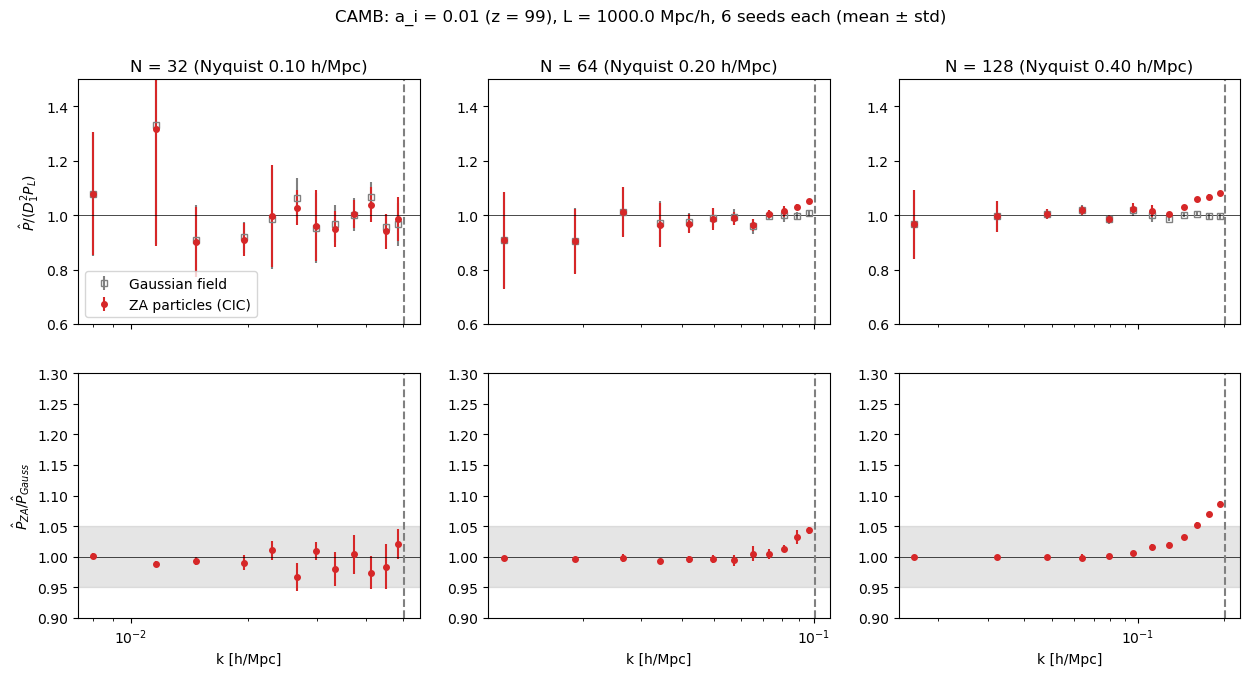

[Power law] N =  32: ZA within 5% of the Gaussian field up to k = 0.027 h/Mpc = 0.27 k_Nyq
[Power law] N =  64: ZA within 5% of the Gaussian field up to k = 0.049 h/Mpc = 0.25 k_Nyq
[Power law] N = 128: ZA within 5% of the Gaussian field up to k = 0.112 h/Mpc = 0.28 k_Nyq


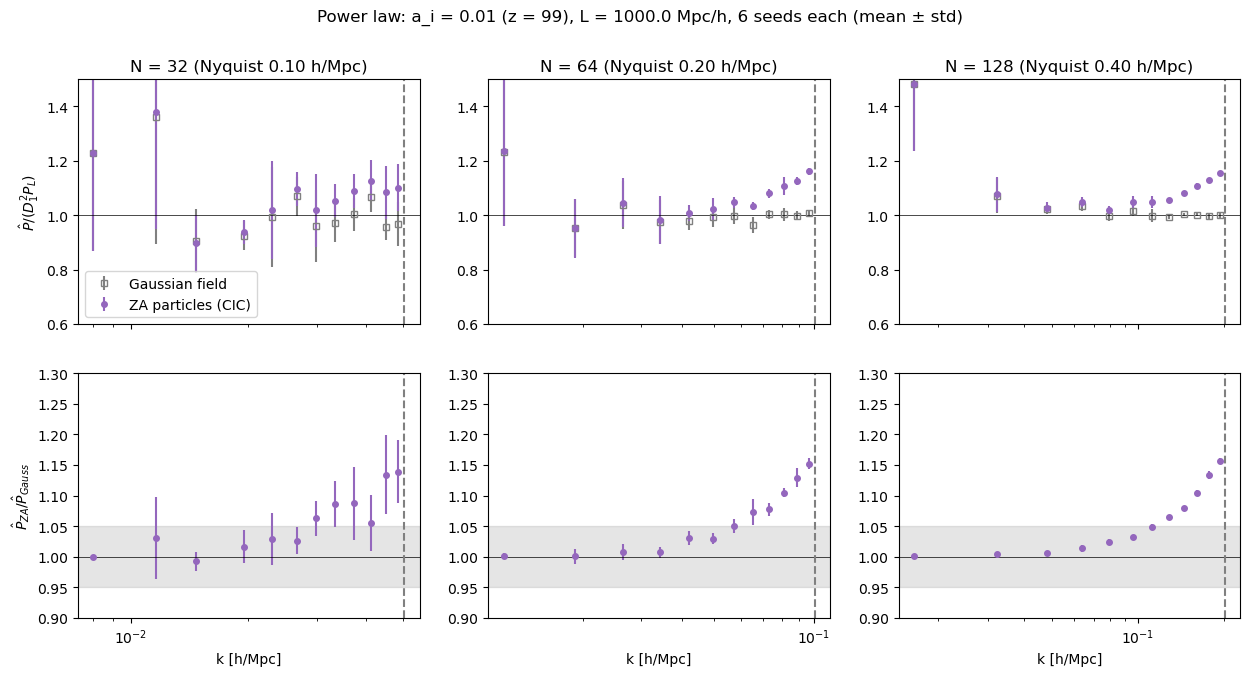

In [52]:
# for different seeds and resolutions
from matplotlib.ticker import NullFormatter
nseeds, nb_ = 6, 12                          # realizations per resolution and number of k shells
for name, Pk_in, c in (('CAMB', Pk_camb, 'C3'), ('Power law', Pk_pl, 'C4')):
    fig, axs = plt.subplots(2, 3, figsize=(15, 7), sharex='col')
    for col, Nr in enumerate((32, 64, 128)):
        rg, rz, rzg = [], [], []             # per seed: Gaussian/target, ZA/target, ZA/Gaussian
        for seed in range(nseeds):
            dk = gaussian_field(Pk_in, Nr, L, np.random.default_rng(seed))
            pm = Pk_measurement(dk, Zeldovich(dk, Nr, L, cosmo, a_i, a_ref, H0=H0), Nr, L, nb_)
            kg, Pg, _ = pm.Pk_measured(nb_, 'gauss', kmax_frac)
            kp, Pp, _ = pm.Pk_measured(nb_, 'particles', kmax_frac)
            rg.append(Pg / Pk_target(Pk_in, kg)); rz.append(Pp / Pk_target(Pk_in, kp)); rzg.append(Pp / Pg)
        rg, rz, rzg = np.array(rg), np.array(rz), np.array(rzg)
        kNyq_r = np.pi * Nr / L
        axs[0, col].errorbar(kg, rg.mean(0), rg.std(0), fmt='s', c='gray', ms=4, mfc='none', label='Gaussian field')
        axs[0, col].errorbar(kp, rz.mean(0), rz.std(0), fmt='o', c=c, ms=4, label='ZA particles (CIC)')
        axs[1, col].errorbar(kp, rzg.mean(0), rzg.std(0), fmt='o', c=c, ms=4)
        axs[1, col].axhspan(0.95, 1.05, color='gray', alpha=.2)
        for ax in axs[:, col]:
            ax.axhline(1, c='k', lw=.5); ax.axvline(0.5 * kNyq_r, c='gray', ls='--'); ax.set_xscale('log')
            ax.xaxis.set_minor_formatter(NullFormatter())
        axs[0, col].set_title(f'N = {Nr} (Nyquist {kNyq_r:.2f} h/Mpc)'); axs[0, col].set_ylim(0.6, 1.5); axs[1, col].set_ylim(0.9, 1.3)
        axs[1, col].set_xlabel('k [h/Mpc]')
        ok = np.abs(rzg.mean(0) - 1) < 0.05                          # shells where ZA agrees with the Gaussian field within 5%
        first_bad = np.argmin(ok)
        kmax_ok = kp[-1] if ok.all() else (kp[first_bad - 1] if first_bad > 0 else np.nan)
        print(f"[{name}] N = {Nr:3d}: ZA within 5% of the Gaussian field up to k = {kmax_ok:.3f} h/Mpc = {kmax_ok/kNyq_r:.2f} k_Nyq")
    axs[0, 0].set_ylabel(r'$\hat P/(D_1^2P_L)$'); axs[1, 0].set_ylabel(r'$\hat P_{ZA}/\hat P_{Gauss}$'); axs[0, 0].legend()
    fig.suptitle(f"{name}: a_i = {a_i} (z = {1/a_i - 1:.0f}), L = {L} Mpc/h, {nseeds} seeds each (mean ± std)", fontsize=12)
    plt.show()
